In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
print("Missing values in Cuisines:")
print(df["Cuisines"].isnull().sum())

Missing values in Cuisines:
9


In [5]:
print(df["Cuisines"].head(10))

0            French, Japanese, Desserts
1                              Japanese
2      Seafood, Asian, Filipino, Indian
3                       Japanese, Sushi
4                      Japanese, Korean
5                               Chinese
6                       Asian, European
7    Seafood, Filipino, Asian, European
8               European, Asian, Indian
9                              Filipino
Name: Cuisines, dtype: str


In [6]:
cuisine_combinations = (
    df.dropna(subset=["Cuisines"])
    .groupby("Cuisines")["Restaurant ID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Cuisine Combinations:")

display(cuisine_combinations.head(10))

Top 10 Cuisine Combinations:


Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: Restaurant ID, dtype: int64

In [7]:
rating_data = df.dropna(subset=["Cuisines"]).copy()

cuisine_ratings = (
    rating_data.groupby("Cuisines")
    .agg(
        Restaurant_Count=("Restaurant ID", "nunique"),
        Average_Rating=("Aggregate rating", "mean")
    )
    .sort_values(by="Average_Rating", ascending=False)
)

display(cuisine_ratings.head(10))

,Restaurant_Count,Average_Rating
Cuisines,,
"Burger, Bar Food, Steak",1,4.9
"American, Burger, Grill",1,4.9
"American, Caribbean, Seafood",1,4.9
"American, Coffee and Tea",1,4.9
"Mexican, American, Healthy Food",1,4.9
"Italian, Bakery, Continental",1,4.9
"BBQ, Breakfast, Southern",1,4.9
"European, German",1,4.9
"Hawaiian, Seafood",1,4.9


In [8]:
popular_cuisine_ratings = cuisine_ratings[
    cuisine_ratings["Restaurant_Count"] >= 10
].sort_values(
    by="Average_Rating",
    ascending=False
)

display(popular_cuisine_ratings.head(10))

,Restaurant_Count,Average_Rating
Cuisines,,
Modern Indian,11,4.345455
Indian,18,4.250000
Seafood,14,4.114286
Thai,16,4.100000
"Cafe, Continental, Italian",10,4.080000
"American, Burger",13,4.076923
"Japanese, Sushi",18,4.044444
"Pizza, Italian",19,3.668421
American,31,3.667742


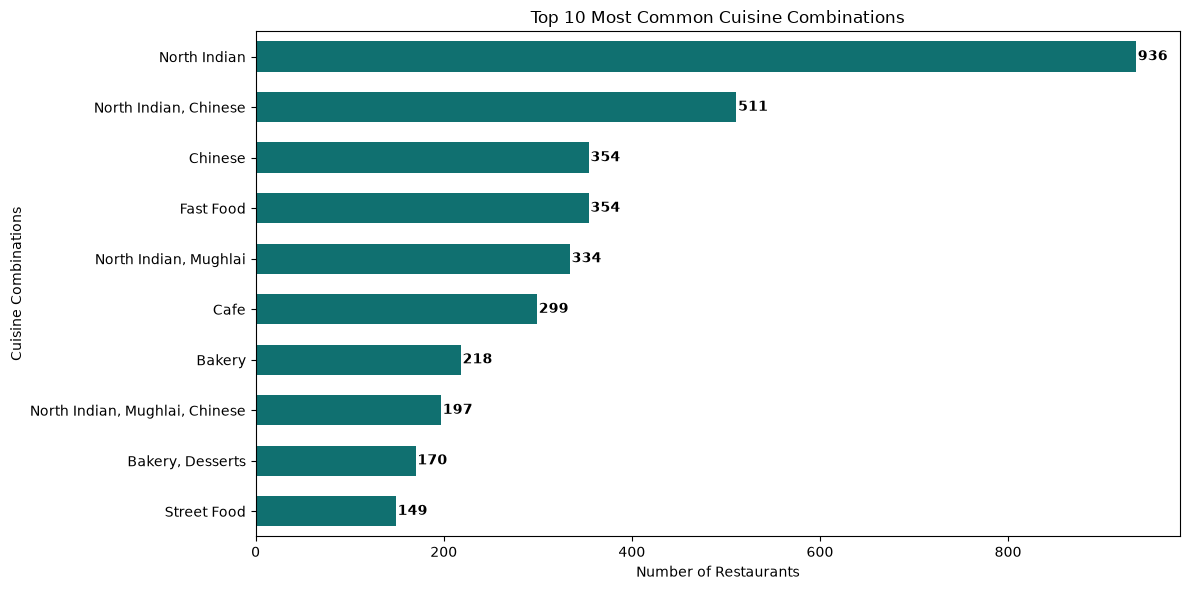

In [9]:
top_cuisines = cuisine_combinations.head(10)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index,
    color="teal",
    width=0.6
)

for i, value in enumerate(top_cuisines.values):
    ax.text(
        value + 2,
        i,
        str(value),
        va="center",
        fontweight="bold"
    )

plt.title("Top 10 Most Common Cuisine Combinations")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine Combinations")

plt.tight_layout()
plt.savefig("Top_Cuisine_Combinations.png", dpi=300)
plt.show()

In [10]:
cuisine_combinations.head(10).to_csv(
    "Top_Cuisine_Combinations.csv"
)

cuisine_ratings.to_csv(
    "Cuisine_Combination_Ratings.csv"
)

print("Task 2 analysis completed!")

Task 2 analysis completed!
